In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FILE_PATH = "household_power_consumption.csv"

df = pd.read_csv(FILE_PATH, na_values=["?"], low_memory=False)

print(df.shape)
display(df.head())

(1048575, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [10]:
df["datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["datetime", "Global_active_power"])
df = df.sort_values("datetime")
df = df.drop_duplicates(subset="datetime")
df = df.set_index("datetime")

print(df.shape)
print(df[numeric_cols].isnull().sum())

(1044506, 9)
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [11]:
hourly = df[numeric_cols].resample("h").mean()

# Fill short missing gaps, then remaining gaps for a continuous time series
hourly = hourly.interpolate(method="time", limit=3)
hourly = hourly.ffill().bfill()

print(hourly.head())
print("Total hourly records:", len(hourly))

                     Global_active_power  Global_reactive_power     Voltage  \
datetime                                                                      
2006-12-16 17:00:00             4.222889               0.229000  234.643889   
2006-12-16 18:00:00             3.632200               0.080033  234.580167   
2006-12-16 19:00:00             3.400233               0.085233  233.232500   
2006-12-16 20:00:00             3.268567               0.075100  234.071500   
2006-12-16 21:00:00             3.056467               0.076667  237.158667   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
datetime                                                                
2006-12-16 17:00:00         18.100000             0.0        0.527778   
2006-12-16 18:00:00         15.600000             0.0        6.716667   
2006-12-16 19:00:00         14.503333             0.0        1.433333   
2006-12-16 20:00:00         13.916667             0.0        0.000000   
2006-12-

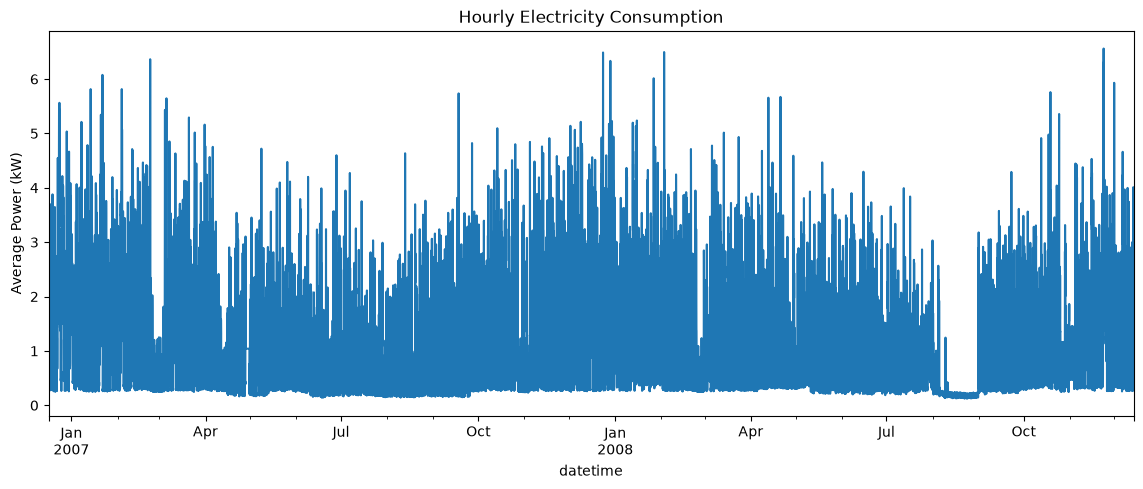

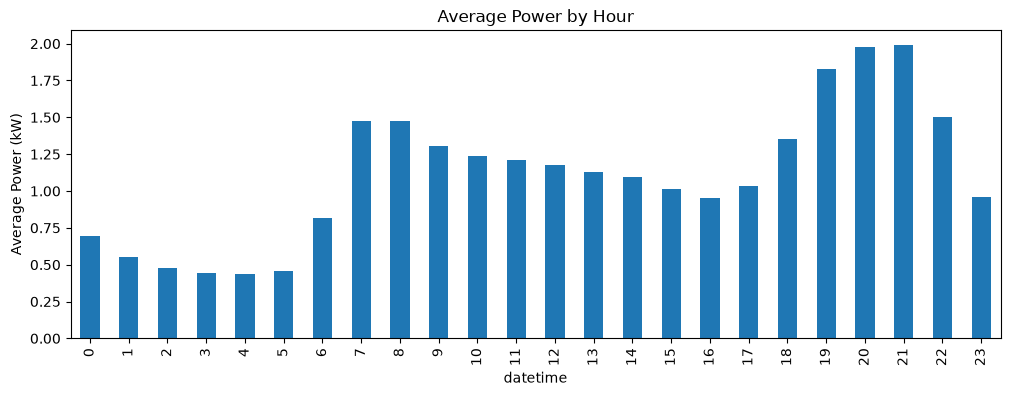

In [12]:
hourly["Global_active_power"].plot(
    figsize=(14, 5),
    title="Hourly Electricity Consumption"
)
plt.ylabel("Average Power (kW)")
plt.show()

hourly.groupby(hourly.index.hour)["Global_active_power"].mean().plot(
    kind="bar",
    figsize=(12, 4),
    title="Average Power by Hour"
)
plt.ylabel("Average Power (kW)")
plt.show()

In [13]:
data = pd.DataFrame(index=hourly.index)

data["demand"] = hourly["Global_active_power"]

data["hour"] = data.index.hour
data["day"] = data.index.dayofweek
data["month"] = data.index.month
data["is_weekend"] = (data["day"] >= 5).astype(int)

data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)

# Lag features from the actual columns in your CSV
for col in numeric_cols:
    short_name = col.lower().replace("global_", "").replace("sub_metering_", "sub_")
    data[f"{short_name}_lag1"] = hourly[col].shift(1)
    data[f"{short_name}_lag24"] = hourly[col].shift(24)

data["demand_lag168"] = data["demand"].shift(168)
data["rolling_mean24"] = data["demand"].shift(1).rolling(24).mean()
data["rolling_mean168"] = data["demand"].shift(1).rolling(168).mean()

data = data.replace([np.inf, -np.inf], np.nan).dropna()

X = data.drop(columns="demand")
y = data["demand"]

print(X.shape, y.shape)
display(data.head())

(17309, 23) (17309,)


,demand,hour,day,month,is_weekend,hour_sin,hour_cos,active_power_lag1,active_power_lag24,reactive_power_lag1,...,intensity_lag24,sub_1_lag1,sub_1_lag24,sub_2_lag1,sub_2_lag24,sub_3_lag1,sub_3_lag24,demand_lag168,rolling_mean24,rolling_mean168
datetime,,,,,,,,,,,,,,,,,,,,,
2006-12-23 17:00:00,5.452533,17,5,12,1,-0.965926,-2.588190e-01,4.349100,1.496800,0.402600,...,6.243333,1.266667,0.000000,1.083333,0.000000,17.716667,10.516667,4.222889,2.934890,1.763946
2006-12-23 18:00:00,3.879400,18,5,12,1,-1.000000,-1.836970e-16,5.452533,2.686967,0.215967,...,11.390000,16.183333,0.000000,0.666667,0.516667,16.750000,3.900000,3.632200,3.099713,1.771265
2006-12-23 19:00:00,4.117833,19,5,12,1,-0.965926,2.588190e-01,3.879400,3.938167,0.099767,...,16.540000,0.000000,0.000000,0.016667,0.000000,17.350000,17.266667,3.400233,3.149397,1.772736
2006-12-23 20:00:00,4.181400,20,5,12,1,-0.866025,5.000000e-01,4.117833,3.536067,0.205333,...,15.050000,0.000000,7.816667,0.600000,0.566667,17.466667,17.016667,3.268567,3.156883,1.777008
2006-12-23 21:00:00,3.288433,21,5,12,1,-0.707107,7.071068e-01,4.181400,4.548667,0.124767,...,19.453333,0.000000,9.183333,0.350000,0.000000,17.416667,16.750000,3.056467,3.183772,1.782441


In [14]:
split = int(len(data) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (13847, 23)
Test: (3462, 23)


In [15]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

Training: Linear Regression
Training: Polynomial Regression
Training: Random Forest
Training: Gradient Boosting


,Model,MAE,RMSE,R2
3,Gradient Boosting,0.345411,0.503633,0.683406
1,Polynomial Regression,0.346334,0.499566,0.688498
0,Linear Regression,0.364862,0.531390,0.647548
2,Random Forest,0.389478,0.531028,0.648028


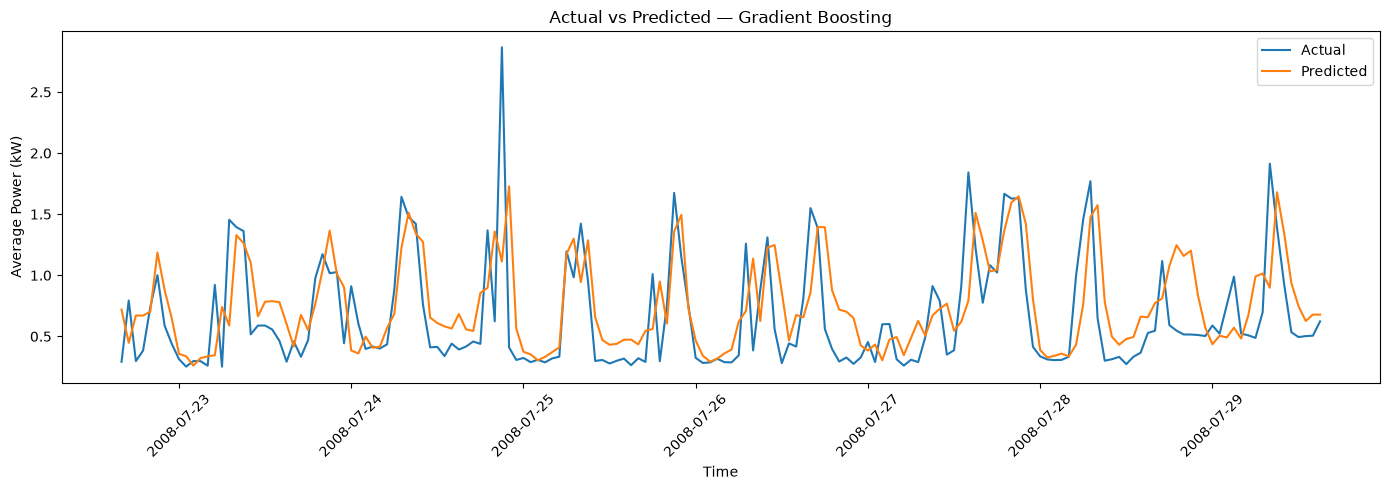

Best model: Gradient Boosting


In [16]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

n = min(168, len(y_test))

plt.figure(figsize=(14, 5))
plt.plot(y_test.index[:n], y_test.iloc[:n], label="Actual")
plt.plot(
    y_test.index[:n],
    predictions[best_name][:n],
    label="Predicted"
)

plt.title(f"Actual vs Predicted — {best_name}")
plt.xlabel("Time")
plt.ylabel("Average Power (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Best model:", best_name)

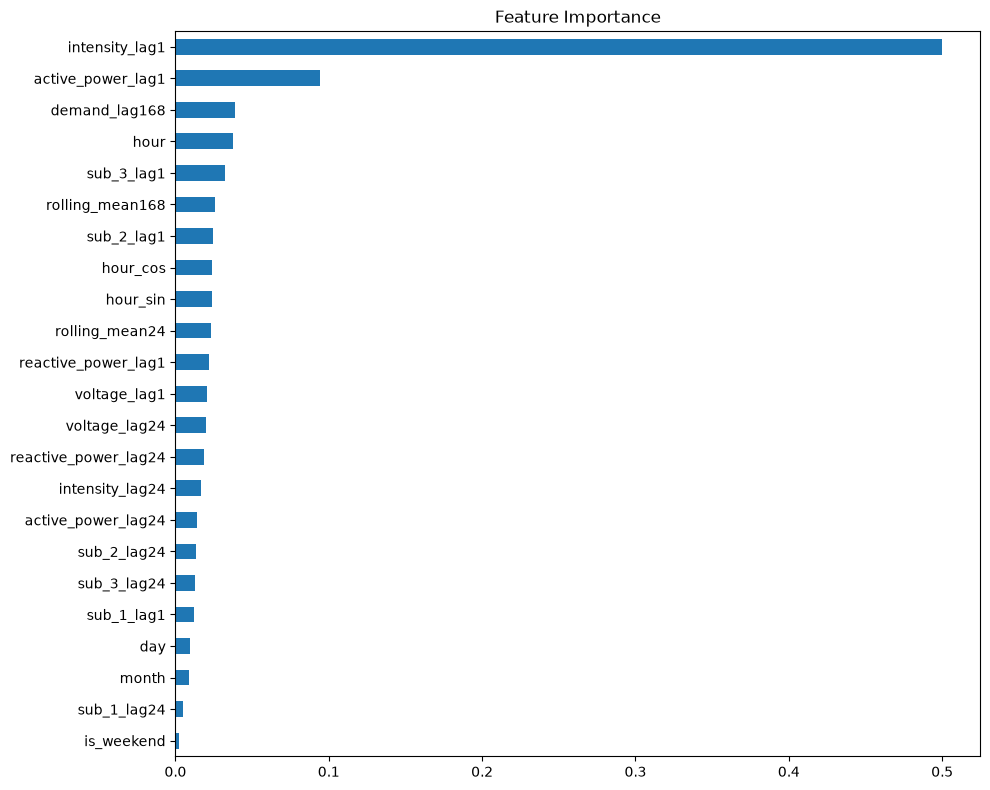

In [17]:
rf = trained_models["Random Forest"]

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(10, 8))
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

In [18]:
joblib.dump(best_model, "energy_demand_model.pkl")
joblib.dump(list(X.columns), "model_features.pkl")

results_df.to_csv("model_comparison.csv", index=False)

print("Model saved successfully.")

Model saved successfully.


In [19]:
next_time = hourly.index[-1] + pd.Timedelta(hours=1)

row = {
    "hour": next_time.hour,
    "day": next_time.dayofweek,
    "month": next_time.month,
    "is_weekend": int(next_time.dayofweek >= 5),
    "hour_sin": np.sin(2 * np.pi * next_time.hour / 24),
    "hour_cos": np.cos(2 * np.pi * next_time.hour / 24)
}

for col in numeric_cols:
    short_name = col.lower().replace("global_", "").replace("sub_metering_", "sub_")
    row[f"{short_name}_lag1"] = hourly[col].iloc[-1]
    row[f"{short_name}_lag24"] = hourly[col].iloc[-24]

row["demand_lag168"] = hourly["Global_active_power"].iloc[-168]
row["rolling_mean24"] = hourly["Global_active_power"].iloc[-24:].mean()
row["rolling_mean168"] = hourly["Global_active_power"].iloc[-168:].mean()

X_next = pd.DataFrame([row])[X.columns]

saved_model = joblib.load("energy_demand_model.pkl")
forecast = saved_model.predict(X_next)[0]

print("Forecast time:", next_time)
print(f"Predicted average power: {forecast:.3f} kW")

Forecast time: 2008-12-13 22:00:00
Predicted average power: 0.628 kW


In [20]:
data.to_csv("processed_energy_data.csv")
print("Processed dataset saved.")

Processed dataset saved.


In [21]:
!git init
!git add .
!git commit -m "My Jupyter Notebook project"
!git remote add origin <https://github.com/users/sagarjain2003-byte/projects/3/views/1>
!git branch -M main
!git push -u origin main

'git' is not recognized as an internal or external command,
operable program or batch file.
'git' is not recognized as an internal or external command,
operable program or batch file.
'git' is not recognized as an internal or external command,
operable program or batch file.
The syntax of the command is incorrect.
'git' is not recognized as an internal or external command,
operable program or batch file.
'git' is not recognized as an internal or external command,
operable program or batch file.
